<div dir="RTL" align="center" style="color:cornflowerblue;">

 ## < The Final Project of Machine Learning >

</div>

<div dir="RTL">

- ### دیتاست انتخابی : Radio Javan

> فاطمه زمانی

> استاد محمدرضا شاقوزی

> دوره یادگیری ماشین مجتمع فنی نیاوران

- ### Tasks :

> تحلیل اکتشافی داده و انجام پیش پردازش (EDA & preprocessing)

> مدل سازی و ارزیابی (Modeling and Evaluation)

> گزارش متنی

</div>


In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import classification_report, silhouette_score, mean_squared_error, mean_absolute_error, root_mean_squared_error, f1_score, accuracy_score, recall_score, precision_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.cluster import KMeans
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.utils import shuffle, resample
from sklearn.impute import SimpleImputer
from sklearn.svm import LinearSVC, SVC 

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.ensemble import BaggingClassifier, BaggingRegressor
from sklearn.decomposition import TruncatedSVD

----------------- 
-----------

- ## بخش اول :   Preprocessing & EDA



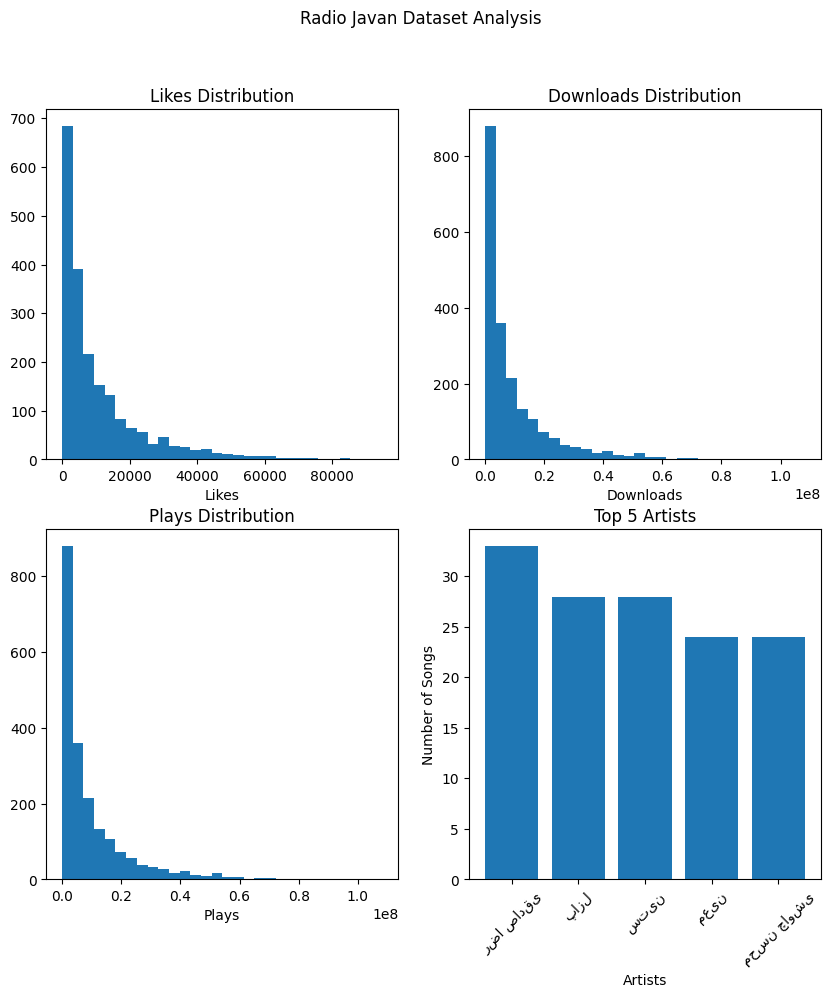

In [ ]:
df = pd.read_csv("Radio_Javan/rj_sample.csv")
df = df.drop_duplicates()

columns = ["likes","downloads","plays"]
for i in columns:
    df[i] = df[i].str.replace(",","").astype(float)

df.replace(r'^\s*$',np.nan,regex=True,inplace=True)

nums = SimpleImputer(strategy="median")
df[columns] = nums.fit_transform(df[columns])

text_cols = ["artist_farsi", "song_farsi", "lyric"]
texts = SimpleImputer(strategy="most_frequent")
df[text_cols] = texts.fit_transform(df[text_cols])

for z in columns:
    df[z] = df[z].fillna(df[z].median())
for x in text_cols:
    df[x] = df[x].fillna(df[x].mode()[0])

for j in text_cols:
    df[j] = df[j].str.strip() 

fig,ax=plt.subplots(2,2,figsize=(10,10))
fig.suptitle("Radio Javan Dataset Analysis")

ax[0,0].hist(df["likes"], bins=30)
ax[0,0].set_title("Likes Distribution")
ax[0,0].set_xlabel("Likes")

ax[0,1].hist(df["downloads"], bins=30)
ax[0,1].set_title("Downloads Distribution")
ax[0,1].set_xlabel("Downloads")

ax[1,0].hist(df["plays"], bins=30)
ax[1,0].set_title("Plays Distribution")
ax[1,0].set_xlabel("Plays")

artists = df["artist_farsi"].value_counts().head(5)

ax[1, 1].bar(artists.index, artists.values)
ax[1, 1].set_title("Top 5 Artists")
ax[1, 1].set_xlabel("Artists")
ax[1, 1].set_ylabel("Number of Songs")
ax[1, 1].tick_params(axis="x", rotation=45)


df.to_csv("rj_cleaned.csv", index=False)

<div dir="RTL" align="center">

-----
--------
- ## بخش دوم : Modeling and evaluation

- ### الگوریتم های استفاده شده بر روی بخش های مختلف دیتاست :

</div>

### 1. Regression

<div dir="RTL">

پیش‌ بینی مقدار محبوبیت آهنگ براساس ویژگی‌ هایی مثل متن اهنگ و خواننده.

</div>

- Algorithms :

> 1. LinearRegression

> 2. Random Forest

### 2. Text Classification
<div dir="RTL">

دسته‌ بندی آهنگ‌ ها براساس خواننده. مثلا پیش‌ بینی کند هر متن متعلق به کدام خواننده است.
</div>

- Algorithms :

> 1. SVM

> 2. Logistic Regression

> 3. Random Forest

### 3. Clustering

<div dir="RTL">

خوشه‌ بندی آهنگ‌ ها بدون نیاز به لیبل.

</div>

- Algorithms :

> 1. KMeans

> 2. DBSCAN

</div>

<div  align="center" style="color:#5F9EA0;">

-----

> ## 1: Regression

</div>

In [ ]:
df = pd.read_csv("rj_cleaned.csv")

#                       LinearRegression مدل سازی با 

X = df[["downloads","plays"]].values
y = df["likes"].values
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=1405)

pipe=Pipeline([
    ("scaler", StandardScaler()),
    ("model", LinearRegression())
])
params={
    "model__fit_intercept": [True,False]
}

clf = GridSearchCV(pipe,param_grid=params,cv=5)

clf.fit(X_train, y_train)
preds = clf.predict(X_test)

print('-----------> Linear Regression', '\nBest Params :\t', clf.best_params_,'\nMAE :\t', 
      mean_absolute_error(y_test, preds), '\nRMSE :\t', root_mean_squared_error(y_test, preds))

#                       Random Forest Classifier مدل سازی با 

X2 = df[["downloads", "plays"]].values
y2 = df["likes"].values
X_train,X_test,y_train,y_test=train_test_split(X2,y2,test_size=0.2,random_state=1405)

Q1=pd.Series(y_train).quantile(0.33)
Q2=pd.Series(y_train).quantile(0.66)

y_train2 = pd.Series(0,index=range(len(y_train)))
y_test2 = pd.Series(0,index=range( len(y_test)))

y_train2[y_train>Q1] =1
y_train2[y_train>Q2] =2
y_test2[y_test>Q1] =1
y_test2[y_test>Q2] =2

pipe=Pipeline([
    ("model", RandomForestClassifier())
])
params={
    "model__n_estimators": [100,200],
    "model__max_depth": [None,5,10],
    "model__min_samples_split": [2,5]
}

clf = GridSearchCV(pipe,param_grid=params,cv=5)
clf.fit(X_train,y_train2)
preds=clf.predict(X_test)

print('\n-----------> Random Forest Classification', '\nBest Params : \t', clf.best_params_, '\nClassification Report : \n',classification_report(y_test2,preds) )

-----------> Linear Regression 
Best Params :	 {'model__fit_intercept': True} 
MAE :	 2025.518172782145 
RMSE :	 3330.200932326214

-----------> Random Forest Classification 
Best Params : 	 {'model__max_depth': 5, 'model__min_samples_split': 5, 'model__n_estimators': 100} 
Classification Report : 
               precision    recall  f1-score   support

           0       0.93      0.91      0.92       148
           1       0.77      0.87      0.82       113
           2       0.96      0.89      0.92       144

    accuracy                           0.89       405
   macro avg       0.89      0.89      0.89       405
weighted avg       0.90      0.89      0.89       405



<div align="center" style="color:#6495ED;">

----
> ## 2: Classification and Bagging

</div>

In [4]:
df = pd.read_csv("rj_cleaned.csv")
df["lyric"] = df["lyric"].astype(str)

artist_count = df["artist_farsi"].value_counts()
new_artists = artist_count[artist_count<5].index
df_new = df[df["artist_farsi"].isin(new_artists)]
df_normal = df[~df["artist_farsi"].isin(new_artists)]

#   < علت این تقسیم در بعد از سلول این کد توضیح داده شده >

X_train_normal,X_test,y_train_normal,y_test=train_test_split(df_normal["lyric"],df_normal["artist_farsi"],test_size=0.2,random_state=1405)
X_train = pd.concat([X_train_normal, df_new["lyric"]])
y_train = pd.concat([y_train_normal, df_new["artist_farsi"]])


#                        LinearSVC استفاده از

pipe=Pipeline([
    ("tfidf", TfidfVectorizer(encoding='utf-8',use_idf=True,smooth_idf=True,min_df=2,max_df=1.0,analyzer='word',max_features=5000,norm='l2')),
    ("model", LinearSVC(class_weight="balanced"))
])
pipe.fit(X_train, y_train)
preds = pipe.predict(X_test)

print('-----------> SVM', '\nAccuracy : \t', accuracy_score(y_test, preds), '\nf1_weighted : \t', f1_score(y_test, preds, average="weighted"))


# 2.                    Logistic Regression استفاده از

pipe=Pipeline([
    ("tfidf", TfidfVectorizer(encoding='utf-8',use_idf=True,smooth_idf=True,min_df=2,max_df=1.0,analyzer='word',max_features=5000,norm='l2')),
    ("model", LogisticRegression(max_iter=2000,class_weight="balanced"))
])
pipe.fit(X_train,y_train)
preds=pipe.predict(X_test)

print("\n-----------> Logistic Regression",'\nAccuracy : \t',accuracy_score(y_test, preds),
      '\nf1_weighted : \t',f1_score(y_test,preds,average="weighted"))


# 3.                    Random Forest استفاده از

pipe=Pipeline([
    ("tfidf", TfidfVectorizer(encoding='utf-8',use_idf=True,smooth_idf=True,min_df=2,max_df=1.0,analyzer='word',max_features=5000,norm='l2')),
    ("model", RandomForestClassifier(n_estimators=200, class_weight="balanced_subsample"))
])
pipe.fit(X_train, y_train)
preds=pipe.predict(X_test)

print("\n-----------> Random Forest", '\nAccuracy : \t',accuracy_score(y_test, preds), 
      '\nf1_weighted : \t', f1_score(y_test, preds, average="weighted"))


# 4.                    Bagging Classification استفاده از

pipe=Pipeline([
    ("tfidf", TfidfVectorizer(encoding='utf-8',use_idf=True,smooth_idf=True,min_df=2,max_df=1.0,analyzer='word',max_features=5000,norm='l2')),
    ("model", BaggingClassifier(estimator=DecisionTreeClassifier(),n_estimators=10,max_samples=0.8,random_state=1405))
])
pipe.fit(X_train, y_train)
preds=pipe.predict(X_test)

print("\n-----------> Bagging Classification",'\nAccuracy : \t', accuracy_score(y_test, preds),
      '\nf1_weighted : \t', f1_score(y_test, preds, average="weighted"))

-----------> SVM 
Accuracy : 	 0.08579881656804733 
f1_weighted : 	 0.09689294925981318

-----------> Logistic Regression 
Accuracy : 	 0.038461538461538464 
f1_weighted : 	 0.05506544737313968

-----------> Random Forest 
Accuracy : 	 0.09763313609467456 
f1_weighted : 	 0.1054685385002127

-----------> Bagging Classification 
Accuracy : 	 0.07988165680473373 
f1_weighted : 	 0.07829178111983542


<div dir="RTL" style="color:violet;">

- ### نکات مهم درباره Classification :

</div>

<div dir="RTL">

> 1. *علت جداسازی خواننده های تازه کار از خواننده های قدیمی تر :*

در نسخه اولیه ی کد، نسخه قبل از جداسازی خواننده ها، با مقدار f1_weighted و Accuracy پایین تر از خروجی فعلی مواجه شدم که علت آن خواننده هایی با تعداد آهنگ کم و اکثرا ۱ اهنگ بودند. مشکلی که ایجاد میشود این است که آن تک آهنگ ممکن است بعد از مرحله train_test_split وارد test شود، در این صورت مدل هیچ نمونه ای از ان خواننده در train ندارد و در نتیجه مدل فرصت یادگیری خواننده را نداشته است. 

**بعنوان راه حل** تعیین کردم که تا زمانی که تعداد اهنگ های خواننده کمتر از 5 است همه ان اهنگ ها وارد بخش train شوند تا زمانی که خواننده اهنگ های بیشتر بنویسد و تعداد 5 و یا از 5 بیشتر شود.

> 2. *استفاده از TfidfVectorizer :*

برای اینکه مدل بتواند متن و کلمات را تحلیل کند از TfidfVectorizer استفاده کردیم تا متن را به اعداد تبدیل کنیم. هایپرپارامترهایی هم برای بهبود عملکرد مدل تعریف شده اند.

</div>

<div  align="center" style="color:#4682B4;">


----
> ## 3. clustering

</div>

In [ ]:
df = pd.read_csv("rj_cleaned.csv")
df["lyric"] = df["lyric"].astype(str)
X = df["lyric"]

pipe=Pipeline([
    ("tfidf", TfidfVectorizer(encoding='utf-8',use_idf=True,smooth_idf=True,min_df=2,max_df=1.0,analyzer='word',max_features=5000,norm='l2')),
    ("model", KMeans())
])

params={
    "model__n_clusters": [3,5,7,10,12,15],
    "model__n_init": [10,20],
    "model__max_iter": [300,500]
}

model = GridSearchCV(pipe,params,cv=5)
model.fit(X)

pipe = model.best_estimator_
X_vectorized = pipe.named_steps["tfidf"].transform(X)
kmeans = pipe.named_steps["model"]

print('-----------> KMeans','Best Params:',model.best_params_)
print('Silhouette:',silhouette_score(X_vectorized,kmeans.labels_,metric="cosine"))

-----------> KMeans Best Params: {'model__max_iter': 300, 'model__n_clusters': 15, 'model__n_init': 20}
Silhouette: 0.00974749615222437


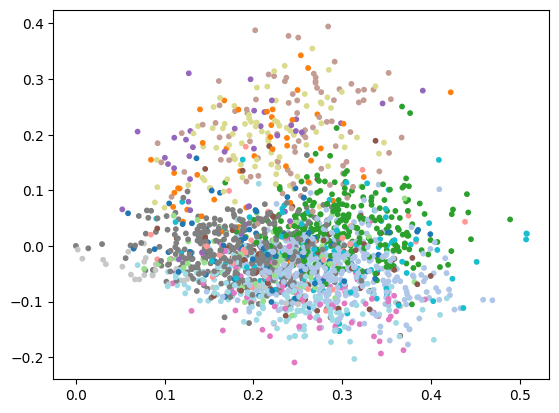

In [ ]:
p = TruncatedSVD(n_components=2,algorithm='arpack',n_iter=7, random_state=1405,n_oversamples=15).fit_transform(X_vectorized)
plt.scatter(p[:,0],p[:,1], c=kmeans.labels_,s=10,cmap="tab20")

-----------------
----

<div align="center" style="color:#C080A0">

## References

</div>

<div dir="RTL">

> برخی از مراجع استفاده‌شده از مستندات رسمی کتابخانه **Scikit-learn**:

</div>

1. [TfidfVectorizer](https://scikit-learn.org/stable/modules/generated/sklearn.feature_extraction.text.TfidfVectorizer.html#sklearn.feature_extraction.text.TfidfVectorizer)
2. [BaggingClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.BaggingClassifier.html#sklearn.ensemble.BaggingClassifier)
3. [BaggingRegressor](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.BaggingRegressor.html#sklearn.ensemble.BaggingRegressor)
4. [TruncatedSVD](https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.TruncatedSVD.html#sklearn.decomposition.TruncatedSVD)